# NESS probe: $\Delta(T_1)$ sweeps, occupations and bands

All parameters are fixed in the first cells. Only the SPP plateau $\omega_s$ and width $\gamma$ are meant to be varied.
A bath setup is a function `bath(t1, t2) -> Pack` (temperatures in units of $T_c$), built with `combo(hot, cold)`.
Every probe takes such a `bath`, so switching baths is one argument.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from types import SimpleNamespace

from EI_refactor.EI_ness import baths as B
from EI_refactor.EI_ness import model as M
from EI_refactor.EI_ness import gpu as S                  # or cpu
from EI_refactor.EI_ness.gpu.rates import rates as R      # same backend as S
from EI_refactor.EI_ness.teff import t_eff

from utils.cosmetics import SET1_LIST

from tqdm.notebook import tqdm

from utils.cosmetics import apply_plt_style
from utils.plotting_utils import Plotter

apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)


FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"


## Parameters
Energies in $t_a$, temperatures in units of $T_c$. `WS` is $\omega_s/\Delta_0$.

In [2]:
# model and grid
G, TA, TB, V = 4.0, 1.0, -1.0, 4.1
NS, NF = 160, 128

# SPP (free: WS, GAM)
WS, GAM = 1.0, 0.2          # omega_s / Delta_0, line width
FR, DIP, Z0 = 0.039, 0.1, 20.0
CT = 3946.54                 # c in t_a a0 units

# phonons (Chord)
CS, GPH, APH = 0.026, 0.05, 4.2e-4

# toy baths
KAP, WC = 1.0e-2, np.inf     # product toy: strength, energy cutoff
KX = 1.0e-3                  # cold interband toy (db)

# temperatures (units of Tc)
T2 = 0.1                     # fixed bath for the sweep
T1N = np.linspace(0.1, 15.0, 60)
T1P, T2P = 10.0, 0.1         # probe point

In [3]:
md = M.Model(G, TA, TB, V)
g = M.sgrid(NS, NF)
e0 = M.solve_eq(md, g, 0.0, d=1.0)
tc = M.critical_temperature(md, g)
mst = (md.gap - 4.0 * (md.ta - md.tb)) / md.h   # Hartree bands touch at Gamma
print(f"Delta0 = {e0.d:.4f}, Tc = {tc:.4f}, m0 = {e0.m:.4f}, m* = {mst:.4f}")

Delta0 = 0.0826, Tc = 0.0485, m0 = -0.9959, m* = -0.9756


## Baths
Each function returns one bath at temperature `t` (units of $T_c$).
`spp` reads `WS`, `GAM` unless given, so `partial(spp, ws=..., gam=...)` makes a variant.
`combo(hot, cold)` puts the `hot` baths at $T_1$ and the `cold` baths at $T_2$.

In [4]:
from functools import partial


def spp(t, ws=None, gam=None):
    w = (WS if ws is None else ws) * e0.d
    amp = 2.0 * np.pi * B.ALPHA * CT * w**2 * FR
    return B.SPP(t * tc, w, GAM if gam is None else gam, amp, DIP, Z0)


ph = lambda t: B.Chord(t * tc, CS, GPH, APH, 1.0, -1.0)
prod = lambda t: B.Toy(t * tc, KAP, WC)
db = lambda t: B.Toy(t * tc, kap=(0.0, KX, 0.0), rate="db")


def combo(hot, cold):
    """bath(t1, t2) -> Pack: hot baths at T1, cold baths at T2."""
    return lambda t1, t2: B.pack([f(t1) for f in hot] + [f(t2) for f in cold], md, g)


baths = {
    r"SPP$_1$ + ph$_2$": combo([spp], [ph]),
    r"SPP$_1$ + prod$_2$": combo([spp], [prod]),
    r"ph$_1$ + prod$_2$": combo([ph], [prod]),
    r"prod$_1$ + prod$_2$": combo([prod], [prod]),
}

## Solver

In [5]:
def ness(bath, t1, t2, d=None, m=None):
    """NESS of bath(t1, t2); starts from equilibrium at the colder bath unless d, m are given."""
    if d is None:
        eq = M.solve_eq(md, g, min(t1, t2) * tc, d=e0.d, m=e0.m)
        d, m = max(eq.d, 1.0e-3 * e0.d), eq.m
    pk = bath(t1, t2)
    s = S.solve(md, g, pk, d=d, m=m)
    if not s.ok:
        s = S.solve_fixed(md, g, pk, d=d, m=m)
    return s, pk

## 1. $\Delta(T_1)$ sweep at fixed $T_2$
Up sweep continues from equilibrium at the colder bath, down sweep from the gapless side at the hottest $T_1$.
Where they differ, the NESS is bistable.

In [6]:
def sweep(bath, t2=T2, tl=T1N, down=False):
    """Delta/Delta0, m, ok along tl; returns (up, dn), dn is None for down=False."""
    def run(tl, d, m):
        out = np.full((tl.size, 3), np.nan)
        for i, t1 in tqdm(enumerate(tl)):
            try:
                s, _ = ness(bath, t1, t2, d, m)
            except ValueError as ex:
                print(f"T1={t1:.2f}: {ex}")
                continue
            out[i] = float(s.d) / e0.d, float(s.m), float(s.ok)
            if s.ok and float(s.d) > 1.0e-3 * e0.d:
                d, m = float(s.d), float(s.m)
        return out

    eq = M.solve_eq(md, g, min(tl[0], t2) * tc, d=e0.d, m=e0.m)
    up = run(tl, max(eq.d, 1.0e-3 * e0.d), eq.m)
    dn = run(tl[::-1], 1.0e-3 * e0.d, e0.m)[::-1] if down else None
    return up, dn


def plot_sweep(res, t2=T2, tl=T1N):
    """res: {label: (up, dn)}; Delta and m vs T1, solid up, dashed down."""
    fig, (ax, axm) = plt.subplots(2, 1, figsize=(3.47412, 3.47412), sharex=True)
    for i, (lab, (up, dn)) in tqdm(enumerate(res.items())):
        for r, ls, lb in ((up, "-", lab), (dn, "--", None)):
            if r is None:
                continue
            ok = r[:, 2] > 0
            ax.plot(tl, np.where(ok, r[:, 0], np.nan), ls, color=SET1_LIST[i], lw=1.0, label=lb)
            axm.plot(tl, np.where(ok, r[:, 1], np.nan), ls, color=SET1_LIST[i], lw=1.0)
    axm.axhline(mst, color="k", ls="--", lw=0.8)   # band overlap
    ax.axvline(t2, color="gray", lw=0.6)          # T1 = T2
    ax.set_ylabel(r"$\Delta/\Delta_0$")
    axm.set_ylabel(r"$m$")
    axm.set_xlabel(r"$T_1/T_c$")
    ax.set_xlim(tl[0], tl[-1])
    ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
              borderaxespad=0, ncol=2, fontsize=7)
    for a in (ax, axm):
        a.grid(alpha=0.3)
        a.tick_params(which="both", direction="in")
    plt.tight_layout()
    return fig

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

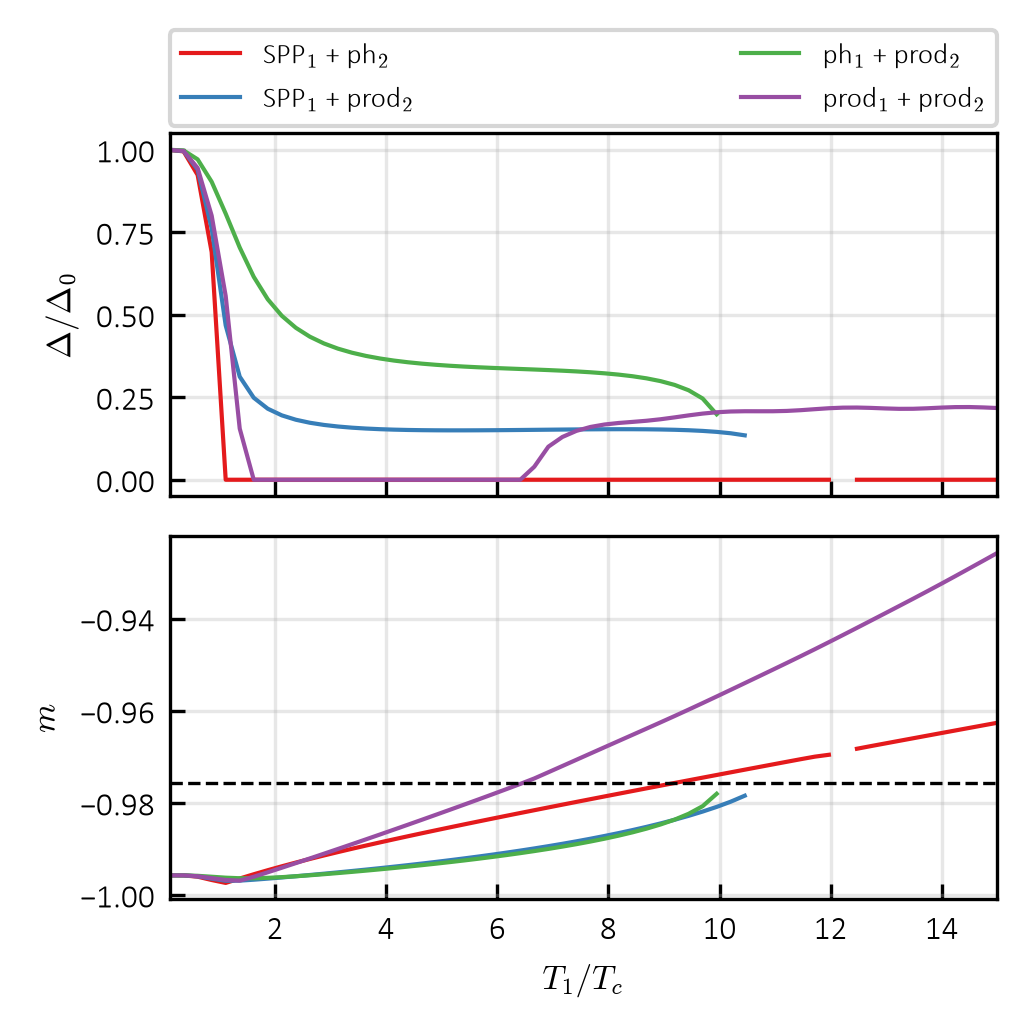

In [60]:
res = {lab: sweep(b) for lab, b in baths.items()}
fig = plot_sweep(res)

## 2. Occupations at one point
$n_\alpha$ vs $\xi$ with Fermi functions at $T_1$, $T_2$ and the GE temperature $T_\mathrm{eff}$ (all at $\mu = 0$),
plus the residual $n_\alpha - f(T_\mathrm{eff})$. Pass `s` from `ness` to skip the solve.

In [7]:
def probe_occ(bath, t1=T1P, t2=T2P, s=None, xmax=20.0):
    """n_alpha vs xi at (T1, T2) with f(T1), f(T2), f(T_eff)."""
    if s is None:
        s, _ = ness(bath, t1, t2)
    pk = bath(t1, t2)
    st = s.st
    xi = 0.5 * (st.e[0] - st.e[1]) * (st.u**2 - st.v**2)
    k = xi / e0.d <= xmax
    o = np.argsort(xi[k])
    x, e, na = xi[k][o] / e0.d, st.e[0][k][o], np.asarray(s.n)[0][k][o]
    fd = lambda t: 1.0 / (1.0 + np.exp(e / (t * tc)))   # mu = 0, shifted frame
    te = t_eff(md, g, pk, R, t1 * tc, t2 * tc, e0.d, e0.m) / tc

    fig, (ax, ax2) = plt.subplots(2, 1, sharex=True, figsize=(3.47412, 0.8 * 3.47412),
                                  gridspec_kw={"height_ratios": [3.5, 1.0], "hspace": 0.08})
    ax.plot(x, na, "-", color=SET1_LIST[0], lw=1.0, label=r"$n_\alpha$")
    ax.plot(x, fd(t1), "k--", lw=0.6, label=r"$f(T_1)$")
    ax.plot(x, fd(t2), "k-.", lw=0.6, label=r"$f(T_2)$")
    ax.plot(x, fd(te), "-", color=SET1_LIST[3], lw=0.6, label=r"$f(T_\mathrm{eff})$")
    ax.set_yscale("log")
    ax.set_ylim(0.3 * na[na > 0].min(), 1.5 * na.max())   # f(T2) would set the scale otherwise
    ax.set_ylabel(r"$n_\alpha$")
    ax.legend(fontsize=7, ncol=2)

    res = na - fd(te)
    ax2.axhline(0.0, color="0.5", lw=0.5, ls="--")
    ax2.plot(x, res, "-", color=SET1_LIST[2], lw=0.8)
    ax2.set_xlabel(r"$\xi/\Delta_0$")
    ax2.set_ylabel(r"$n_\alpha - f(T_\mathrm{eff})$", fontsize=8)
    ym = np.max(np.abs(res))
    ax2.set_ylim(-1.1 * ym, 1.1 * ym)
    ax.set_xlim(x[0], x[-1])
    for a in (ax, ax2):
        a.grid(alpha=0.3)
        a.tick_params(which="both", direction="in")
    plt.tight_layout()
    print(f"T1 = {t1}, T2 = {t2}: ok = {s.ok}, d/D0 = {float(s.d) / e0.d:.4f}, "
          f"m - m* = {float(s.m) - mst:.2e}, Teff/Tc = {te:.3f}")
    return s, fig

## 3. Bands along $k_y = 0$
Hartree (diagonal) bands $\epsilon^H_{a,b}$, quasiparticle bands $E_{\alpha,\beta}$ and $n_\alpha(k_x)$, centred at $\Gamma$.
Bands are exact on $s(k) = \cos k_x + 1$; $n_\alpha$ is interpolated from the $s$ bins.

In [8]:
def probe_bands(bath, t1=T1P, t2=T2P, s=None, kmax=1.0, nk=401):
    """Hartree and quasiparticle bands and n_alpha along k_y = 0 at (T1, T2)."""
    if s is None:
        s, _ = ness(bath, t1, t2)
    kx = np.linspace(-kmax, kmax, nk)
    sk = np.cos(kx) + 1.0
    st = M.mf(md, SimpleNamespace(s=sk), float(s.d), float(s.m))
    av, ek = 0.5 * (st.e[0] + st.e[1]), 0.5 * (st.e[0] - st.e[1])
    xi = ek * (st.u**2 - st.v**2)
    ea, eb = av + xi, av - xi
    # na = np.interp(sk, g.s, np.asarray(s.n)[0])

    edges = np.linspace(-2.0, 2.0, g.s.size + 1)           # sgrid bin edges
    ib = np.clip(np.digitize(sk, edges) - 1, 0, g.s.size - 1)
    na = np.asarray(s.n)[0][ib]    
    
    fig, (ax, ax2) = plt.subplots(2, 1, sharex=True, figsize=(3.47412, 0.9 * 3.47412),
                                  gridspec_kw={"height_ratios": [2.5, 1.0], "hspace": 0.08})
    ax.plot(kx, ea, "--", color=SET1_LIST[0], lw=0.8, label=r"$\epsilon_a^H$")
    ax.plot(kx, eb, "--", color=SET1_LIST[1], lw=0.8, label=r"$\epsilon_b^H$")
    ax.plot(kx, st.e[0], "-", color="k", lw=1.0, label=r"$E_\alpha$")
    ax.plot(kx, st.e[1], "-", color="0.5", lw=1.0, label=r"$E_\beta$")
    ax.axhline(0.0, color="0.5", lw=0.5, ls=":")   # mu = 0
    ax.set_ylabel(r"$E$")
    ax.legend(fontsize=7, ncol=2)
    ax2.plot(kx, na, "-", color="k", lw=0.8, label=r"$n_\alpha$")
    ax2.set_xlabel(r"$k_x$ ($k_y = 0$)")
    ax2.set_ylabel(r"$n_\alpha$")
    ax2.legend(fontsize=7)
    ax2.set_xlim(kx[0], kx[-1])
    for a in (ax, ax2):
        a.grid(alpha=0.3)
        a.tick_params(which="both", direction="in")
    plt.tight_layout()
    print(f"T1 = {t1}, T2 = {t2}: d/D0 = {float(s.d) / e0.d:.4f}, m - m* = {float(s.m) - mst:.2e}, "
          f"Hartree gap = {ea.min() - eb.max():.4f}")
    return fig

## Usage
Solve once per point and pass `s` to both probes.

T1 = 10.0, T2 = 0.1: ok = True, d/D0 = 0.1444, m - m* = -5.04e-03, Teff/Tc = 7.183
T1 = 10.0, T2 = 0.1: d/D0 = 0.1444, m - m* = -5.04e-03, Hartree gap = 0.0207


/tmp/ipykernel_28213/3818544882.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_28213/4049787977.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


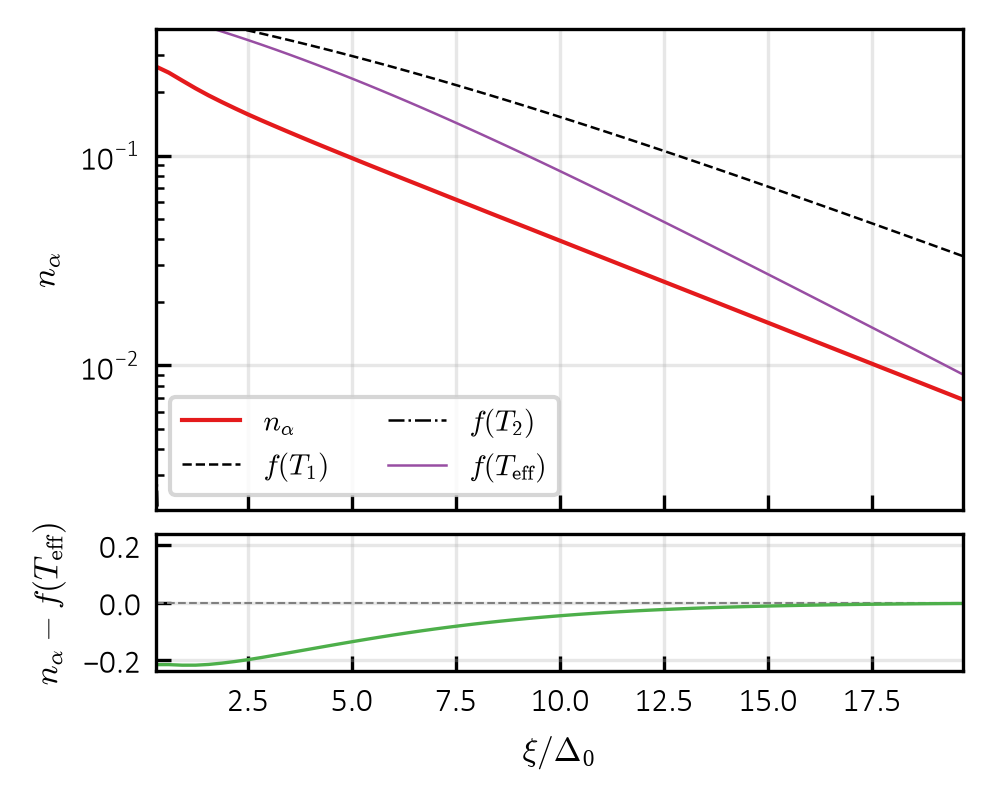

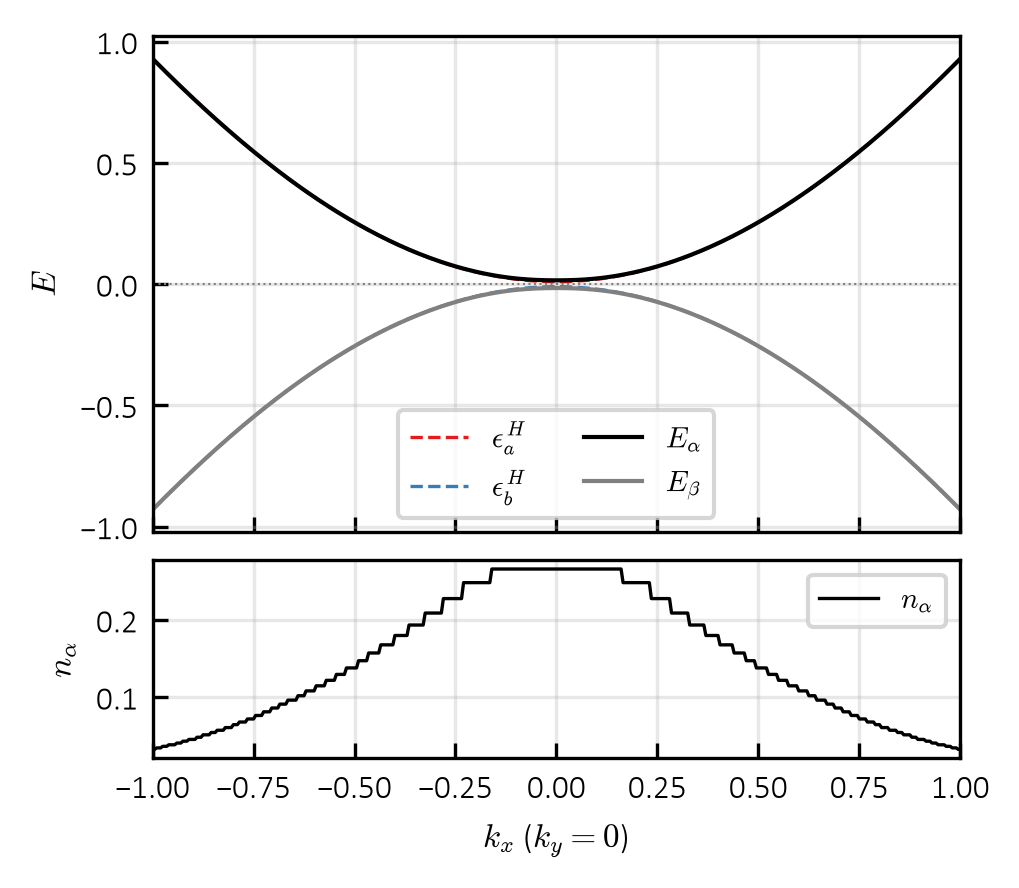

In [63]:
bath = baths[r"SPP$_1$ + prod$_2$"]
s, _ = ness(bath, t1=T1P, t2=T2P)
s, fig1 = probe_occ(bath, s=s)
fig2 = probe_bands(bath, s=s)

Varying the SPP: a new bath with another $\omega_s$, $\gamma$ (other parameters unchanged).

0it [00:00, ?it/s]

0it [00:00, ?it/s]

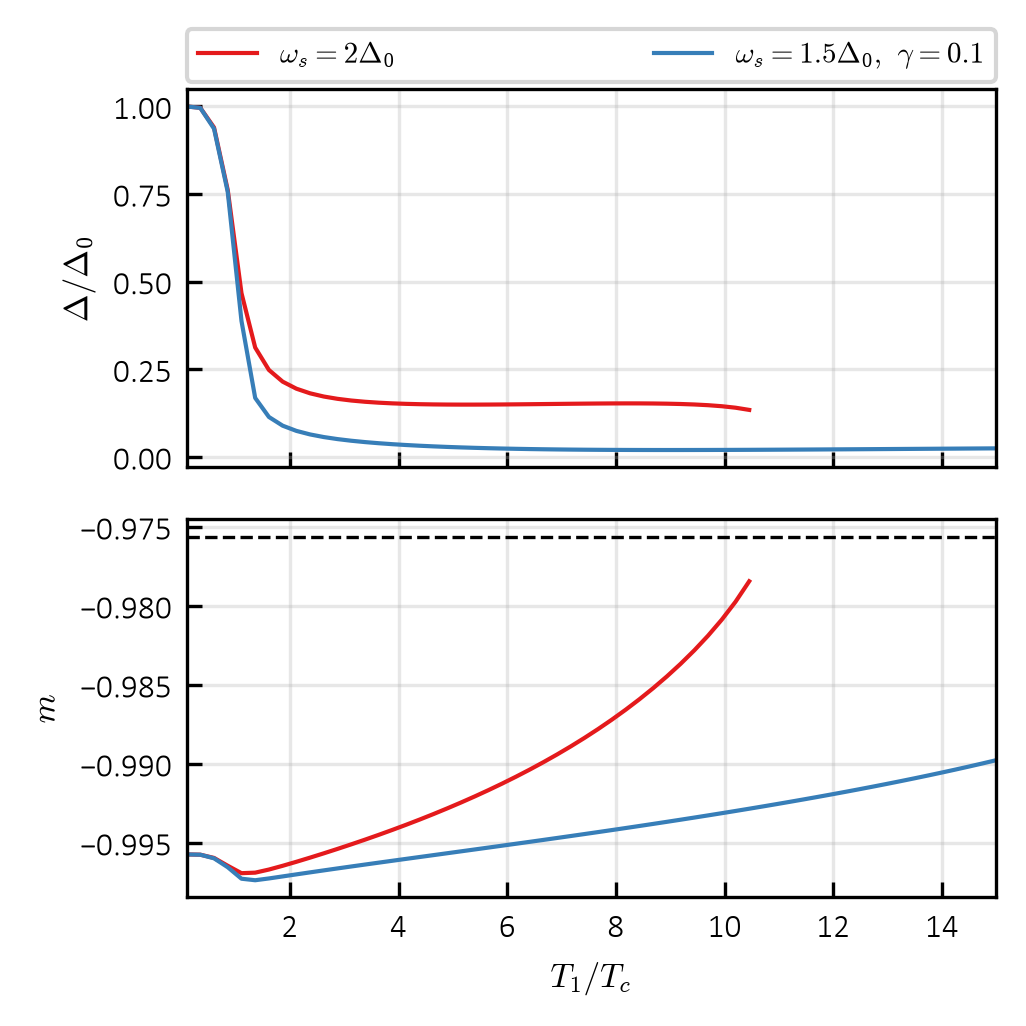

In [64]:
b2 = combo([partial(spp, ws=1.5, gam=0.1)], [ph, db])
res2 = {r"$\omega_s = 2\Delta_0$": res[r"SPP$_1$ + prod$_2$"],
        r"$\omega_s = 1.5\Delta_0,\ \gamma = 0.1$": sweep(b2)}
fig = plot_sweep(res2)

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

SPP$_1$ + ph$_2$
G = 4, ta = 1, tb = -1, V = 4.1, ns = 160, nf = 128, ws = 1, gam = 0.2, fr = 0.039, dip = 0.1, z0 = 20, cs = 0.026, gph = 0.05, aph = 0.00042, kap = 0.01, wc = inf, kx = 0.001
Delta0 = 0.0826, Tc = 0.0485, ws = 0.0826 (abs)


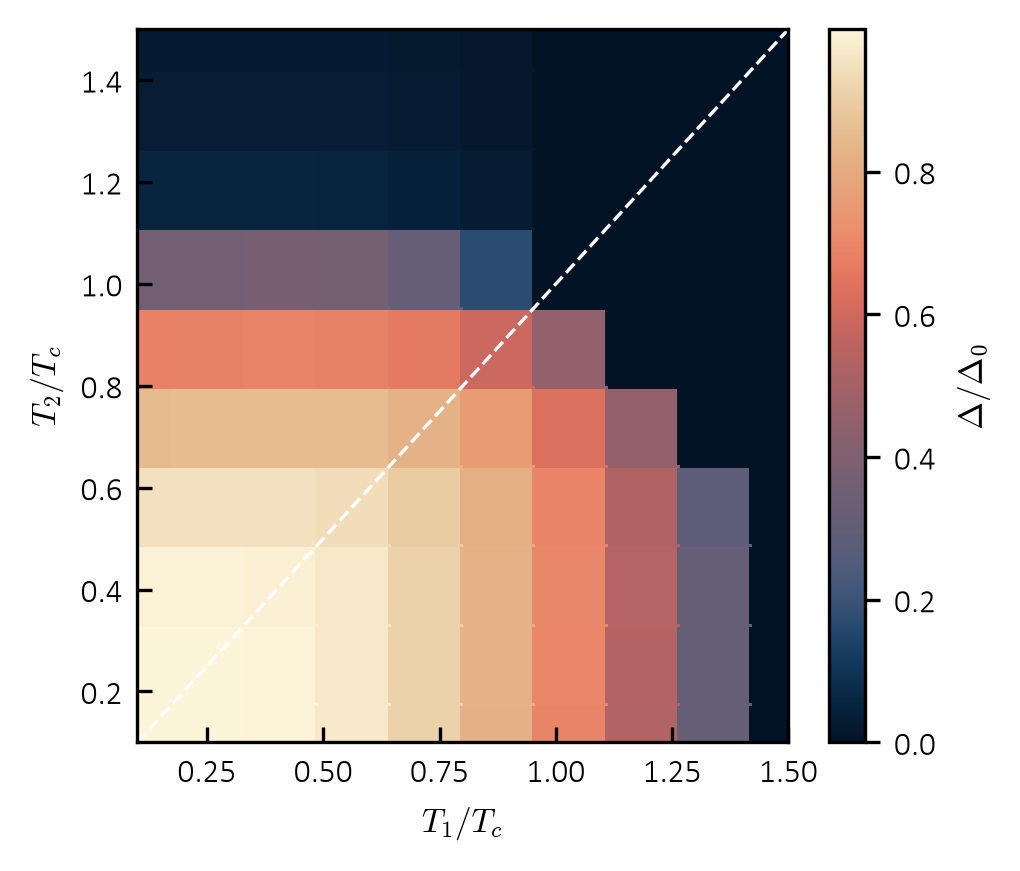

In [79]:
import colormaps as cmaps

PAR = dict(G=G, ta=TA, tb=TB, V=V, ns=NS, nf=NF, ws=WS, gam=GAM, fr=FR, dip=DIP, z0=Z0,
           cs=CS, gph=GPH, aph=APH, kap=KAP, wc=WC, kx=KX)


def scan2d(bath, t1n, t2n):
    """Delta/Delta0, m, ok on the (T2, T1) grid; rows continue along T1."""
    dd, mm, ok = (np.full((t2n.size, t1n.size), np.nan) for _ in range(3))
    for j, t2 in tqdm(enumerate(t2n), total=t2n.size):
        d, m = None, None                       # row start: equilibrium at the colder bath
        for i, t1 in tqdm(enumerate(t1n), total=t1n.size, leave=False):
            try:
                s, _ = ness(bath, t1, t2, d, m)
            except ValueError as ex:
                print(f"T1={t1:.2f} T2={t2:.2f}: {ex}")
                continue
            dd[j, i], mm[j, i], ok[j, i] = float(s.d) / e0.d, float(s.m), float(s.ok)
            if s.ok and float(s.d) > 1.0e-3 * e0.d:
                d, m = float(s.d), float(s.m)
    return dd, mm, ok


def plot2d(dd, ok, t1n, t2n, lab=""):
    """Delta/Delta0 map with the T1 = T2 diagonal."""
    fig, ax = plt.subplots(figsize=(3.47412, 0.85 * 3.47412))
    im = ax.pcolormesh(t1n, t2n, np.where(ok > 0, dd, np.nan), shading="auto", cmap=cmaps.lipari, vmin=0.0)
    im.set_edgecolor("face")
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"$\Delta/\Delta_0$", rotation=90, labelpad=5)
    lo, hi = max(t1n.min(), t2n.min()), min(t1n.max(), t2n.max())
    ax.plot([lo, hi], [lo, hi], "w--", lw=0.8)  # T1 = T2
    ax.set_xlabel(r"$T_1/T_c$")
    ax.set_ylabel(r"$T_2/T_c$")
    ax.set_xlim(t1n.min(), t1n.max())
    ax.set_ylim(t2n.min(), t2n.max())
    ax.tick_params(which="both", direction="in")
    plt.tight_layout()
    print(lab)
    print(", ".join(f"{k} = {v:g}" for k, v in PAR.items()))
    print(f"Delta0 = {e0.d:.4f}, Tc = {tc:.4f}, ws = {WS * e0.d:.4f} (abs)")
    return fig


lab = r"SPP$_1$ + ph$_2$"
t1n = np.linspace(0.1, 1.5, 10)
t2n = np.linspace(0.1, 1.5, 10)
dd, mm, ok = scan2d(baths[lab], t1n, t2n)
np.savez("scan2d.npz", t1n=t1n, t2n=t2n, d=dd, m=mm, ok=ok, d0=e0.d, tc=tc, bath=lab, par=PAR)
fig = plot2d(dd, ok, t1n, t2n, lab)
# fig.savefig(FIG_PATH + "scan2d.pdf", bbox_inches="tight")

In [9]:
def split(parts, s):
    """Per-bath dn/dt and out-rates at the NESS s; parts = [(label, bath_fn, t)]."""
    st, wi = s.st, g.wi
    n = np.asarray(s.n)[:, wi].reshape(-1)            # alpha block, then beta
    w = np.tile(g.w[wi], 2)
    nw = wi.size
    out = {}
    for lab, f, t in parts:
        r = np.asarray(R(md, g, st, B.pack([f(t)], md, g)))   # r[i, j]: j -> i
        dn = (1.0 - n) * (r @ (w * n)) - n * (r.T @ (w * (1.0 - n)))
        ro = r.T * (w * (1.0 - n))[:, None]           # ro[i, j]: rate i -> j
        intra = ro[:nw, :nw].sum(1) + 0.0
        inter = ro[:nw, nw:].sum(1)
        out[lab] = dict(dn=dn[:nw], intra=intra, inter=inter)
    return out

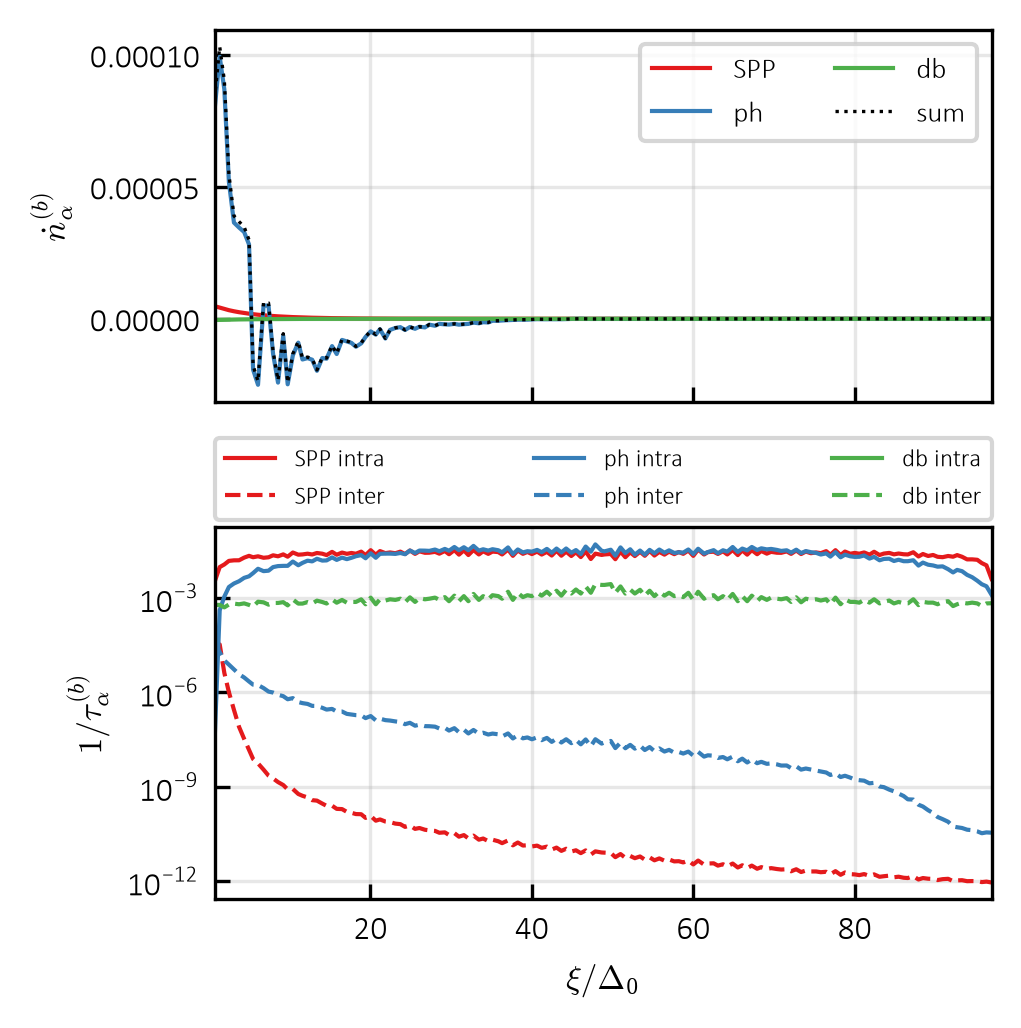

In [ ]:
bath = baths[r"SPP$_1$ + prod$_2$"]
s, _ = ness(bath, T1P, T2P)
# parts = [("SPP", spp, T1P), ("ph", ph, T2P), ("db", db, T2P)]
parts = [("SPP", spp, T1P), ("ph", ph, T2P)]
sp = split(parts, s)
xi = 0.5 * (s.st.e[0] - s.st.e[1]) * (s.st.u**2 - s.st.v**2)
xi = xi[g.wi] / e0.d
o = np.argsort(xi)

fig, (ax, ax2) = plt.subplots(2, 1, sharex=True, figsize=(3.47412, 1.0 * 3.47412))
tot = 0.0
for i, (lab, d) in enumerate(sp.items()):
    ax.plot(xi[o], d["dn"][o], "-", color=SET1_LIST[i], lw=1.0, label=lab)
    ax2.semilogy(xi[o], d["intra"][o], "-", color=SET1_LIST[i], lw=1.0, label=lab + " intra")
    ax2.semilogy(xi[o], d["inter"][o], "--", color=SET1_LIST[i], lw=1.0, label=lab + " inter")
    tot = tot + d["dn"]
ax.plot(xi[o], tot[o], "k:", lw=0.8, label="sum")
ax.set_ylabel(r"$\dot n_\alpha^{(b)}$")
ax2.set_ylabel(r"$1/\tau_\alpha^{(b)}$")
ax2.set_xlabel(r"$\xi/\Delta_0$")
ax2.set_xlim(xi[o][0], xi[o][-1])
ax.legend(fontsize=7, ncol=2)
ax2.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=3, fontsize=6)
for a in (ax, ax2):
    a.grid(alpha=0.3)
    a.tick_params(which="both", direction="in")
plt.tight_layout()